In [3]:
!pip install neurokit2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 693.1/693.1 kB 3.1 MB/s  0:00:00 eta 0:00:01


In [4]:
import os
import cv2
import math
import shutil
import warnings
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from collections import defaultdict

from PIL import Image, ImageFile

from scipy.signal import butter, filtfilt
from scipy.spatial.distance import cdist

from sklearn.feature_selection import (
    SelectKBest,
    mutual_info_classif
)

from sklearn.metrics import (
    roc_curve,
    auc
)

import neurokit2 as nk
import pywt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import (
    Dataset,
    DataLoader,
    Subset,
    TensorDataset,
    random_split
)

import torchvision.transforms as transforms

from torchsummary import summary
from tqdm.auto import tqdm

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

ImageFile.LOAD_TRUNCATED_IMAGES = True

In [5]:
torch.manual_seed(0)
np.random.seed(0)
random.seed(0)
torch.cuda.manual_seed_all(0)

In [6]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("evanwang98/fingerveinsyn-5m-part")

print("Path to dataset files:", path)


Path to dataset files: /kaggle/input/datasets/evanwang98/fingerveinsyn-5m-part


In [7]:
path = kagglehub.dataset_download("souvickroy29/heart-beat")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/souvickroy29/heart-beat


In [8]:
path = kagglehub.dataset_download("mahdieizadpanah/sapienza-university-mobile-palmprint-databasesmpd")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/mahdieizadpanah/sapienza-university-mobile-palmprint-databasesmpd


In [9]:
import os
import shutil

SOURCE_DIR = r"/kaggle/input/datasets/evanwang98/fingerveinsyn-5m-part/FingerVeinSyn5M(4001-5000)"
DEST_DIR = "finger_vein_dataset"

sections = ["Known", "Unknown"]
splits = ["train", "val", "test"]

for section in sections:
    for split in splits:
        os.makedirs(
            os.path.join(DEST_DIR, section, split),
            exist_ok=True
        )

all_labels = sorted([
    d for d in os.listdir(SOURCE_DIR)
    if os.path.isdir(os.path.join(SOURCE_DIR, d))
])

known_labels = all_labels[:200]
unknown_labels = all_labels[200:250]

print(f"Known classes   : {len(known_labels)}")
print(f"Unknown classes : {len(unknown_labels)}")

def process_section(label_list, section_name):

    for new_label, label_name in enumerate(label_list):

        label_path = os.path.join(SOURCE_DIR, label_name)

        images = sorted(os.listdir(label_path))[:100]

        test_imgs = images[:15]
        val_imgs = images[15:30]
        train_imgs = images[30:]

        split_dict = {
            "train": train_imgs,
            "val": val_imgs,
            "test": test_imgs
        }

        for split, img_list in split_dict.items():

            dest_folder = os.path.join(
                DEST_DIR,
                section_name,
                split,
                str(new_label)
            )

            os.makedirs(dest_folder, exist_ok=True)

            for img in img_list:

                shutil.copy2(
                    os.path.join(label_path, img),
                    os.path.join(dest_folder, img)
                )

        print(
            f"{section_name:7s} | "
            f"Original: {label_name} -> "
            f"New: {new_label:3d} | "
            f"Train:{len(train_imgs)} "
            f"Val:{len(val_imgs)} "
            f"Test:{len(test_imgs)}"
        )

process_section(known_labels, "Known")
process_section(unknown_labels, "Unknown")

print("\nDataset creation completed successfully.")

Known classes   : 200
Unknown classes : 50
Known   | Original: 04001 -> New:   0 | Train:70 Val:15 Test:15
Known   | Original: 04002 -> New:   1 | Train:70 Val:15 Test:15
Known   | Original: 04003 -> New:   2 | Train:70 Val:15 Test:15
Known   | Original: 04004 -> New:   3 | Train:70 Val:15 Test:15
Known   | Original: 04005 -> New:   4 | Train:70 Val:15 Test:15
Known   | Original: 04006 -> New:   5 | Train:70 Val:15 Test:15
Known   | Original: 04007 -> New:   6 | Train:70 Val:15 Test:15
Known   | Original: 04008 -> New:   7 | Train:70 Val:15 Test:15
Known   | Original: 04009 -> New:   8 | Train:70 Val:15 Test:15
Known   | Original: 04010 -> New:   9 | Train:70 Val:15 Test:15
Known   | Original: 04011 -> New:  10 | Train:70 Val:15 Test:15
Known   | Original: 04012 -> New:  11 | Train:70 Val:15 Test:15
Known   | Original: 04013 -> New:  12 | Train:70 Val:15 Test:15
Known   | Original: 04014 -> New:  13 | Train:70 Val:15 Test:15
Known   | Original: 04015 -> New:  14 | Train:70 Val:15 Test:

In [10]:
def preprocess_palmprint(
    image_path,
    output_size=224
):

    pil_img = Image.open(
        image_path
    ).convert("RGB")

    img = np.array(pil_img)

    gray = cv2.cvtColor(
        img,
        cv2.COLOR_RGB2GRAY
    )

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8,8)
    )

    gray = clahe.apply(gray)

    gray = cv2.GaussianBlur(
        gray,
        (3,3),
        0
    )

    h, w = gray.shape

    crop_ratio = 0.7

    new_h = int(h * crop_ratio)
    new_w = int(w * crop_ratio)

    start_y = (h - new_h) // 2
    start_x = (w - new_w) // 2

    gray = gray[
        start_y:start_y + new_h,
        start_x:start_x + new_w
    ]

    gray = cv2.resize(
        gray,
        (output_size, output_size)
    )
    
    gray = gray.astype(
        np.float32
    ) / 255.0

    return gray

In [11]:
import os
import shutil

SOURCE_DIR = r"/kaggle/input/datasets/mahdieizadpanah/sapienza-university-mobile-palmprint-databasesmpd/Sapienza University Mobile Palmprint Database(SMPD)"
DEST_DIR = "palm_print_dataset"

sections = ["Known", "Unknown"]
splits = ["train", "val", "test"]

for section in sections:
    for split in splits:
        os.makedirs(
            os.path.join(DEST_DIR, section, split),
            exist_ok=True
        )


TEST_POSITIONS = {1, 2, 11, 12, 21, 22, 31, 32}
VAL_POSITIONS  = {3, 4, 13, 14, 23, 24, 33, 34}


all_labels = sorted([
    d for d in os.listdir(SOURCE_DIR)
    if os.path.isdir(os.path.join(SOURCE_DIR, d))
])

known_labels = all_labels[:70]
unknown_labels = all_labels[70:92]

print(f"Known classes   : {len(known_labels)}")
print(f"Unknown classes : {len(unknown_labels)}")


def process_section(label_list, section_name):

    for new_label, label_name in enumerate(label_list):

        label_path = os.path.join(SOURCE_DIR, label_name)

        images = sorted(os.listdir(label_path))

        train_imgs = []
        val_imgs = []
        test_imgs = []

        for idx, img_name in enumerate(images):

            img_pos = idx + 1

            if img_pos in TEST_POSITIONS:
                test_imgs.append(img_name)

            elif img_pos in VAL_POSITIONS:
                val_imgs.append(img_name)

            else:
                train_imgs.append(img_name)

        split_dict = {
            "train": train_imgs,
            "val": val_imgs,
            "test": test_imgs
        }

        for split, img_list in split_dict.items():

            dest_folder = os.path.join(
                DEST_DIR,
                section_name,
                split,
                str(new_label)
            )

            os.makedirs(dest_folder, exist_ok=True)

            for img_name in img_list:

                shutil.copy2(
                    os.path.join(label_path, img_name),
                    os.path.join(dest_folder, img_name)
                )

        print(
            f"{section_name:7s} | "
            f"Original: {label_name} -> "
            f"New: {new_label:2d} | "
            f"Train:{len(train_imgs)} "
            f"Val:{len(val_imgs)} "
            f"Test:{len(test_imgs)}"
        )

process_section(known_labels, "Known")
process_section(unknown_labels, "Unknown")

print("\nPalmprint dataset created successfully.")

Known classes   : 70
Unknown classes : 22
Known   | Original: 001 -> New:  0 | Train:24 Val:8 Test:8
Known   | Original: 002 -> New:  1 | Train:24 Val:8 Test:8
Known   | Original: 003 -> New:  2 | Train:24 Val:8 Test:8
Known   | Original: 004 -> New:  3 | Train:23 Val:8 Test:8
Known   | Original: 005 -> New:  4 | Train:24 Val:8 Test:8
Known   | Original: 006 -> New:  5 | Train:24 Val:8 Test:8
Known   | Original: 007 -> New:  6 | Train:24 Val:8 Test:8
Known   | Original: 008 -> New:  7 | Train:24 Val:8 Test:8
Known   | Original: 009 -> New:  8 | Train:24 Val:8 Test:8
Known   | Original: 010 -> New:  9 | Train:24 Val:8 Test:8
Known   | Original: 011 -> New: 10 | Train:24 Val:8 Test:8
Known   | Original: 012 -> New: 11 | Train:24 Val:8 Test:8
Known   | Original: 013 -> New: 12 | Train:24 Val:8 Test:8
Known   | Original: 014 -> New: 13 | Train:24 Val:8 Test:8
Known   | Original: 015 -> New: 14 | Train:24 Val:8 Test:8
Known   | Original: 016 -> New: 15 | Train:24 Val:8 Test:8
Known   | Orig

In [12]:
src_root = "/kaggle/input/datasets/souvickroy29/heart-beat/Heartprint"
dst_root = "session_1"

target_sessions = ["Session-1"]

subjects = sorted(
    d for d in os.listdir(os.path.join(src_root, "Session-1"))
    if os.path.isdir(os.path.join(src_root, "Session-1", d))
)

label_map = {subject: idx for idx, subject in enumerate(subjects)}

for session in target_sessions:

    session_path = os.path.join(src_root, session)

    if not os.path.exists(session_path):
        continue

    for subject in os.listdir(session_path):

        subject_path = os.path.join(session_path, subject)

        if not os.path.isdir(subject_path):
            continue

        label = label_map[subject]

        dst_label_dir = os.path.join(dst_root, str(label))
        os.makedirs(dst_label_dir, exist_ok=True)

        for file_name in os.listdir(subject_path):

            src_file = os.path.join(subject_path, file_name)

            if not os.path.isfile(src_file):
                continue

            new_name = f"{session}_{file_name}"

            dst_file = os.path.join(dst_label_dir, new_name)

            shutil.copy2(src_file, dst_file)   

In [13]:
src_root = "/kaggle/input/datasets/souvickroy29/heart-beat/Heartprint"
dst_root = "session_2"

target_sessions = ["Session-2"]

subjects = sorted(
    d for d in os.listdir(os.path.join(src_root, "Session-2"))
    if os.path.isdir(os.path.join(src_root, "Session-2", d))
)

label_map = {subject: idx for idx, subject in enumerate(subjects)}

for session in target_sessions:

    session_path = os.path.join(src_root, session)

    if not os.path.exists(session_path):
        continue

    for subject in os.listdir(session_path):

        subject_path = os.path.join(session_path, subject)

        if not os.path.isdir(subject_path):
            continue

        label = label_map[subject]

        dst_label_dir = os.path.join(dst_root, str(label))
        os.makedirs(dst_label_dir, exist_ok=True)

        for file_name in os.listdir(subject_path):

            src_file = os.path.join(subject_path, file_name)

            if not os.path.isfile(src_file):
                continue

            new_name = f"{session}_{file_name}"

            dst_file = os.path.join(dst_label_dir, new_name)

            shutil.copy2(src_file, dst_file)  

In [14]:
def bandpass_filter(signal, fs=250, lowcut=0.5, highcut=40):
    nyquist = 0.5 * fs

    low = lowcut / nyquist
    high = highcut / nyquist

    b, a = butter(
        N=4,
        Wn=[low, high],
        btype='band'
    )

    filtered = filtfilt(b, a, signal)

    return filtered

def detect_rpeaks(ecg, fs=250):

    signals, info = nk.ecg_process(
        ecg,
        sampling_rate=fs
    )

    return info["ECG_R_Peaks"]

def segment_heartbeat(signal, r_peaks, left=100, right=150):

    beats = []

    for r in r_peaks:

        start = r - left
        end = r + right

        if start >= 0 and end < len(signal):

            beat = signal[start:end]

            beats.append(beat)

    return np.array(beats)

In [15]:
def process_ecg_segment(ecg):
    ecg = bandpass_filter(ecg)
    r_peaks = detect_rpeaks(ecg)
    segments = segment_heartbeat(
        ecg,
        r_peaks
    )
    return segments

In [16]:
def generate_cwt_image(signal, img_size):

    wavelets = [
        'mexh',
        'morl',
        'gaus1'
    ]

    scales = np.arange(1,128)

    channels = []

    for wavelet in wavelets:

        coeffs, _ = pywt.cwt(
            signal,
            scales,
            wavelet
        )

        scalogram = np.abs(coeffs)

        scalogram = cv2.resize(
            scalogram,
            (img_size, img_size)
        )

        scalogram = (
            scalogram - scalogram.min()
        ) / (
            scalogram.max() - scalogram.min() + 1e-8
        )

        scalogram = (
            scalogram * 255
        ).astype(np.uint8)

        channels.append(scalogram)

    image = np.stack(
        channels,
        axis=-1
    )

    return image

In [17]:
def create_split_dataset(src_root, dst_root):

    train_root = os.path.join(dst_root, "train")
    val_root   = os.path.join(dst_root, "val")
    test_root  = os.path.join(dst_root, "test")

    os.makedirs(train_root, exist_ok=True)
    os.makedirs(val_root, exist_ok=True)
    os.makedirs(test_root, exist_ok=True)

    for label in sorted(os.listdir(src_root)):

        label_path = os.path.join(src_root, label)

        if not os.path.isdir(label_path):
            continue

        train_label_dir = os.path.join(train_root, label)
        val_label_dir   = os.path.join(val_root, label)
        test_label_dir  = os.path.join(test_root, label)

        os.makedirs(train_label_dir, exist_ok=True)
        os.makedirs(val_label_dir, exist_ok=True)
        os.makedirs(test_label_dir, exist_ok=True)

        for ecg_file in sorted(os.listdir(label_path)):

            ecg_path = os.path.join(label_path, ecg_file)

            if not os.path.isfile(ecg_path):
                continue

            try:

                data = np.loadtxt(ecg_path)

                ecg = data[:3747]

                segments = process_ecg_segment(ecg)

                base_name = os.path.splitext(ecg_file)[0]

                IMG_SIZE = 224

                for seg_idx, segment in enumerate(segments):

                    file_name = (
                        f"{base_name}_seg_{seg_idx:02d}.png"
                    )

                    if seg_idx < 3:

                        save_path = os.path.join(
                            test_label_dir,
                            file_name
                        )

                    elif seg_idx < 6:

                        save_path = os.path.join(
                            val_label_dir,
                            file_name
                        )

                    else:

                        save_path = os.path.join(
                            train_label_dir,
                            file_name
                        )

                    segment = np.array(segment)

                    segment = (
                        segment - np.min(segment)
                    ) / (
                        np.max(segment)
                        - np.min(segment)
                        + 1e-8
                    )

                    cwt_image = generate_cwt_image(
                        segment,
                        img_size=IMG_SIZE
                    )

                    cv2.imwrite(
                        save_path,
                        cv2.cvtColor(
                            cwt_image,
                            cv2.COLOR_RGB2BGR
                        )
                    )

            except Exception as e:

                print(
                    f"Error processing "
                    f"{ecg_file}: {e}"
                )

In [18]:
create_split_dataset(
    src_root="session_1",
    dst_root="dataset_1"
)


create_split_dataset(
    src_root="session_2",
    dst_root="dataset_2"
)

In [19]:
import os
import shutil

DATASET_1 = "dataset_1"
DATASET_2 = "dataset_2"

OUTPUT_DIR = "ecg_dataset"

SPLITS = ["train", "val", "test"]

for section in ["Known", "Unknown"]:
    for split in SPLITS:
        os.makedirs(
            os.path.join(OUTPUT_DIR, section, split),
            exist_ok=True
        )

def copy_dataset(src_dataset, prefix):

    for split in SPLITS:

        split_path = os.path.join(src_dataset, split)

        if not os.path.exists(split_path):
            continue

        labels = sorted(os.listdir(split_path), key=lambda x: int(x))

        for original_label in labels:

            src_label_dir = os.path.join(
                split_path,
                original_label
            )

            if not os.path.isdir(src_label_dir):
                continue

            original_label = int(original_label)
            
            if original_label < 160:

                section = "Known"
                new_label = original_label

            else:

                section = "Unknown"
                new_label = original_label - 160

            dst_label_dir = os.path.join(
                OUTPUT_DIR,
                section,
                split,
                str(new_label)
            )

            os.makedirs(dst_label_dir, exist_ok=True)

            images = sorted(os.listdir(src_label_dir))

            for idx, img_name in enumerate(images):

                src_img = os.path.join(
                    src_label_dir,
                    img_name
                )

                ext = os.path.splitext(img_name)[1]

                new_name = f"{prefix}_{idx}{ext}"

                dst_img = os.path.join(
                    dst_label_dir,
                    new_name
                )

                shutil.copy2(src_img, dst_img)

copy_dataset(DATASET_1, "d1")
copy_dataset(DATASET_2, "d2")

print("DONE")

DONE


In [20]:
class MultiModalDataset(Dataset):

    def __init__(
        self,
        ecg_root,
        finger_root,
        palm_root,
        class_ids,
        ecg_transform=None,
        finger_transform=None,
        palm_transform=None
    ):

        self.ecg_root = Path(ecg_root)
        self.finger_root = Path(finger_root)
        self.palm_root = Path(palm_root)

        self.ecg_transform = ecg_transform
        self.finger_transform = finger_transform
        self.palm_transform = palm_transform

        self.samples = []

        ecg_folders = sorted(
            [f for f in self.ecg_root.iterdir() if f.is_dir()],
            key=lambda x: int(x.name)
        )

        finger_folders = sorted(
            [f for f in self.finger_root.iterdir() if f.is_dir()],
            key=lambda x: int(x.name)
        )

        palm_folders = sorted(
            [f for f in self.palm_root.iterdir() if f.is_dir()],
            key=lambda x: int(x.name)
        )

        for label in class_ids:

            ecg_imgs = sorted(
                list(ecg_folders[label].glob("*.png"))
            )

            finger_imgs = sorted(
                list(finger_folders[label].glob("*.png"))
            )

            palm_imgs = sorted(
                list(palm_folders[label].glob("*.JPG"))
            )

            random.shuffle(ecg_imgs)
            random.shuffle(finger_imgs)
            random.shuffle(palm_imgs)

            pair_count = min(
                len(ecg_imgs),
                len(finger_imgs),
                len(palm_imgs)
            )

            for i in range(pair_count):

                self.samples.append(
                    (
                        str(ecg_imgs[i]),
                        str(finger_imgs[i]),
                        str(palm_imgs[i]),
                        label
                    )
                )

        print(
            f"Loaded {len(self.samples)} multimodal pairs"
        )
        
    def __len__(self):

        return len(self.samples)


    def __getitem__(self, idx):

        ecg_path, finger_path, palm_path, label = self.samples[idx]

        ecg_img = Image.open(ecg_path).convert("RGB")

        if self.ecg_transform:

            ecg_img = self.ecg_transform(ecg_img)


        finger_pil = Image.open(
            finger_path
        ).convert("L")

        finger_np = np.array(finger_pil)

        clahe_obj = cv2.createCLAHE(
            clipLimit=2.0,
            tileGridSize=(8, 8)
        )

        clahe_img = clahe_obj.apply(finger_np)

        stacked_np = np.stack(
            [clahe_img, clahe_img, clahe_img],
            axis=-1
        )

        finger_img = Image.fromarray(stacked_np)

        if self.finger_transform:

            finger_img = self.finger_transform(
                finger_img
            )
            
        roi = preprocess_palmprint(palm_path)

        stacked_np = np.stack(
            [roi, roi, roi],
            axis=-1
        )

        stacked_np = (
            stacked_np * 255
        ).astype(np.uint8)

        palm_img = Image.fromarray(
            stacked_np
        )

        if self.palm_transform:

            palm_img = self.palm_transform(palm_img)
        

        return (
            ecg_img,
            finger_img,
            palm_img,
            label
        )

In [21]:
KNOWN_CLASSES = list(range(70))
GALLERY_CLASSES = list(range(12))
UNKNOWN_CLASSES = list(range(12,22))

data_transforms_1 = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5,0.5,0.5],
        std=[0.5,0.5,0.5]
    )
])

data_transforms_2 = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.2370, 0.2370, 0.2370], 
        std=[0.1592, 0.1592, 0.1592]
    )
])


train_dataset = MultiModalDataset(
    ecg_root="/kaggle/working/ecg_dataset/Known/train",
    finger_root="/kaggle/working/finger_vein_dataset/Known/train",
    palm_root="/kaggle/working/palm_print_dataset/Known/train",
    class_ids=KNOWN_CLASSES,
    ecg_transform=data_transforms_1,
    finger_transform=data_transforms_2,
    palm_transform=data_transforms_2
)

val_dataset = MultiModalDataset(
    ecg_root="/kaggle/working/ecg_dataset/Known/val",
    finger_root="/kaggle/working/finger_vein_dataset/Known/val",
    palm_root="/kaggle/working/palm_print_dataset/Known/val",
    class_ids=KNOWN_CLASSES,
    ecg_transform=data_transforms_1,
    finger_transform=data_transforms_2,
    palm_transform=data_transforms_2
)

test_dataset = MultiModalDataset(
    ecg_root="/kaggle/working/ecg_dataset/Known/test",
    finger_root="/kaggle/working/finger_vein_dataset/Known/test",
    palm_root="/kaggle/working/palm_print_dataset/Known/test",
    class_ids=KNOWN_CLASSES,
    ecg_transform=data_transforms_1,
    finger_transform=data_transforms_2,
    palm_transform=data_transforms_2
)

gallery_dataset = MultiModalDataset(
    ecg_root="/kaggle/working/ecg_dataset/Unknown/val",
    finger_root="/kaggle/working/finger_vein_dataset/Unknown/val",
    palm_root="/kaggle/working/palm_print_dataset/Unknown/val",
    class_ids=GALLERY_CLASSES,
    ecg_transform=data_transforms_1,
    finger_transform=data_transforms_2,
    palm_transform=data_transforms_2
)

probe_dataset = MultiModalDataset(
    ecg_root="/kaggle/working/ecg_dataset/Unknown/test",
    finger_root="/kaggle/working/finger_vein_dataset/Unknown/test",
    palm_root="/kaggle/working/palm_print_dataset/Unknown/test",
    class_ids=GALLERY_CLASSES,
    ecg_transform=data_transforms_1,
    finger_transform=data_transforms_2,
    palm_transform=data_transforms_2
)

unknown_dataset = MultiModalDataset(
    ecg_root="/kaggle/working/ecg_dataset/Unknown/test",
    finger_root="/kaggle/working/finger_vein_dataset/Unknown/test",
    palm_root="/kaggle/working/palm_print_dataset/Unknown/test",
    class_ids=UNKNOWN_CLASSES,
    ecg_transform=data_transforms_1,
    finger_transform=data_transforms_2,
    palm_transform=data_transforms_2
)

Loaded 1677 multimodal pairs
Loaded 560 multimodal pairs
Loaded 560 multimodal pairs
Loaded 96 multimodal pairs
Loaded 96 multimodal pairs
Loaded 80 multimodal pairs


In [22]:
batch_size = 32

train_loader = DataLoader(
    train_dataset, 
    batch_size=batch_size, 
    shuffle=True,      
    num_workers=0,     
    pin_memory=True    
)

val_loader = DataLoader(
    val_dataset, 
    batch_size=batch_size, 
    shuffle=False,     
    num_workers=0,     
    pin_memory=True    
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

gallery_loader = DataLoader(
    gallery_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)
probe_loader = DataLoader(
    probe_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)
unknown_test_loader = DataLoader(
    unknown_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

images_1,_,_, labels = next(iter(train_loader))
print(f"Batch ecg images shape: {images_1.shape}") 
print(f"Batch labels shape: {labels.shape}") 
print(f"Min label: {labels.min().item()}, Max label: {labels.max().item()}") 

Batch ecg images shape: torch.Size([32, 3, 224, 224])
Batch labels shape: torch.Size([32])
Min label: 0, Max label: 68


In [23]:
class VeinCNN(nn.Module):
    def __init__(self, in_channels=3, emb_dim=512):
        super(VeinCNN, self).__init__()
        
        self.block1 = nn.Sequential(
            nn.Conv2d(in_channels, 64, kernel_size=7, stride=1, padding=3),
            nn.Conv2d(64, 64, kernel_size=5, stride=1, padding=2),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.ReLU(),
            nn.Dropout2d(0.3),
            nn.BatchNorm2d(64)
        )
        
        self.block2 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=7, stride=1, padding=3),
            nn.Conv2d(128, 128, kernel_size=5, stride=1, padding=2),
            nn.MaxPool2d(kernel_size=2, stride=2), 
            nn.ReLU(),
            nn.Dropout2d(0.3),
            nn.BatchNorm2d(128)
        )
                
        self.block3 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=5, stride=1, padding=2),
            nn.Conv2d(256, 256, kernel_size=5, stride=1, padding=2),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.ReLU(),
            nn.Dropout2d(0.3),
            nn.BatchNorm2d(256)
        )
 
        self.block4 = nn.Sequential(
            nn.Conv2d(256, 512, kernel_size=5, stride=1, padding=2),
            nn.Conv2d(512, 512, kernel_size=5, stride=1, padding=2),
            nn.MaxPool2d(kernel_size=2, stride=2), 
            nn.ReLU(),
            nn.Dropout2d(0.3),
            nn.BatchNorm2d(512)
        )
 
        self.block5 = nn.Sequential(
            nn.Conv2d(512, 512, kernel_size=5, stride=1, padding=2),
            nn.MaxPool2d(kernel_size=2, stride=2), 
            nn.ReLU(),
            nn.Dropout2d(0.3),
            nn.BatchNorm2d(512)
        )
 
        self.fc = nn.Sequential(
        nn.Flatten(),
        nn.Linear(7 * 7 * 512, 1024),
        nn.BatchNorm1d(1024),
        nn.ReLU(),
        nn.Dropout(0.4),
        nn.Linear(1024, emb_dim)
        )

    def forward(self, x):
     
        x = self.block1(x)
        
        x = self.block2(x)
        
        x = self.block3(x)

        x = self.block4(x)

        x = self.block5(x)
        x = self.fc(x)
        return x

In [24]:
class ECGCNN(nn.Module):

    def __init__(self, emb_dim):

        super(ECGCNN, self).__init__()
        
        self.features = nn.Sequential(
            nn.Conv2d(in_channels=3,out_channels=16,kernel_size=5,stride=1,padding=2),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),
            nn.Dropout(0.2),
            nn.AdaptiveAvgPool2d((128, 128)),

            nn.Conv2d(in_channels=16,out_channels=32,kernel_size=5,stride=1,padding=2),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Dropout(0.2),
            nn.AdaptiveAvgPool2d((64, 64)),

            nn.Conv2d(in_channels=32,out_channels=64,kernel_size=5,padding=2),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2,stride=2),

            nn.Conv2d(in_channels=64,out_channels=128,kernel_size=5,padding=2),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2,stride=2)
        )
        
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(16 * 16 * 128, 2048),
            nn.BatchNorm1d(2048),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(2048,1024),
            nn.BatchNorm1d(1024),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(1024,emb_dim)
        )

    def forward(self, x):

        x = self.features(x)

        x = self.classifier(x)

        return x

In [25]:
class palmCNN(nn.Module):
    def __init__(self, in_channels=3, emb_dim=512):
        super(palmCNN, self).__init__()
        
        self.block1 = nn.Sequential(
            nn.Conv2d(in_channels, 64, kernel_size=7, stride=1, padding=3),
            nn.Conv2d(64, 64, kernel_size=5, stride=1, padding=2),
            nn.MaxPool2d(kernel_size=2, stride=2), 
            nn.ReLU(),
            nn.Dropout2d(0.3),
            nn.BatchNorm2d(64)
        )
        
        self.block2 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=7, stride=1, padding=3),
            nn.Conv2d(128, 128, kernel_size=5, stride=1, padding=2),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.ReLU(),
            nn.Dropout2d(0.3),
            nn.BatchNorm2d(128)
        )
                
        self.block3 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=5, stride=1, padding=2),
            nn.Conv2d(256, 256, kernel_size=5, stride=1, padding=2),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.ReLU(),
            nn.Dropout2d(0.3),
            nn.BatchNorm2d(256)
        )
 
        self.block4 = nn.Sequential(
            nn.Conv2d(256, 512, kernel_size=5, stride=1, padding=2),
            nn.Conv2d(512, 512, kernel_size=5, stride=1, padding=2),
            nn.MaxPool2d(kernel_size=2, stride=2), 
            nn.ReLU(),
            nn.Dropout2d(0.3),
            nn.BatchNorm2d(512)
        )
 
        self.block5 = nn.Sequential(
            nn.Conv2d(512, 512, kernel_size=5, stride=1, padding=2),
            nn.MaxPool2d(kernel_size=2, stride=2), 
            nn.ReLU(),
            nn.Dropout2d(0.3),
            nn.BatchNorm2d(512)
        )
 
        self.fc = nn.Sequential(
        nn.Flatten(),
        nn.Linear(7 * 7 * 512, 1024),
        nn.BatchNorm1d(1024),
        nn.ReLU(),
        nn.Dropout(0.4),
        nn.Linear(1024, emb_dim)
        )

    def forward(self, x):
     
        x = self.block1(x)
        
        x = self.block2(x)
        
        x = self.block3(x)

        x = self.block4(x)

        x = self.block5(x)
        x = self.fc(x)
        return x

In [26]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("svkroy/modified-final-cnn")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/svkroy/modified-final-cnn


In [27]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model_1 = ECGCNN(emb_dim=512)

model_1.load_state_dict(
    torch.load("/kaggle/input/datasets/svkroy/modified-final-cnn/ECG-Model-Weight(3)")
)

model_1.to(device)

ECGCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Dropout(p=0.2, inplace=False)
    (4): AdaptiveAvgPool2d(output_size=(128, 128))
    (5): Conv2d(16, 32, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (6): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): ReLU(inplace=True)
    (8): Dropout(p=0.2, inplace=False)
    (9): AdaptiveAvgPool2d(output_size=(64, 64))
    (10): Conv2d(32, 64, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (13): Conv2d(64, 128, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (14): ReLU(inplace=True)
    (15): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequ

In [28]:
model_2 = VeinCNN(emb_dim=512)

model_2.load_state_dict(
    torch.load("/kaggle/input/datasets/svkroy/modified-final-cnn/Vein-Model-Weight (1)")
)

model_2.to(device)

VeinCNN(
  (block1): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3))
    (1): Conv2d(64, 64, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): ReLU()
    (4): Dropout2d(p=0.3, inplace=False)
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (block2): Sequential(
    (0): Conv2d(64, 128, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3))
    (1): Conv2d(128, 128, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): ReLU()
    (4): Dropout2d(p=0.3, inplace=False)
    (5): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (block3): Sequential(
    (0): Conv2d(128, 256, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): Conv2d(256, 256, kernel_size=(5, 5), stride=(1, 1), padding=(2

In [29]:
model_3 = palmCNN(emb_dim=512)

model_3.load_state_dict(
    torch.load("/kaggle/input/datasets/svkroy/modified-final-cnn/Palm-Model-Weight (2)")
)

model_3.to(device)

palmCNN(
  (block1): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3))
    (1): Conv2d(64, 64, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): ReLU()
    (4): Dropout2d(p=0.3, inplace=False)
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (block2): Sequential(
    (0): Conv2d(64, 128, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3))
    (1): Conv2d(128, 128, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): ReLU()
    (4): Dropout2d(p=0.3, inplace=False)
    (5): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (block3): Sequential(
    (0): Conv2d(128, 256, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): Conv2d(256, 256, kernel_size=(5, 5), stride=(1, 1), padding=(2

In [30]:
model_4 = torch.hub.load('facebookresearch/dinov2', 'dinov2_vitl14')

model_4 = model_4.to(device)
model_4.eval()

print(model_4)
print(summary(model_4, (3, 224, 224)))

Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip


/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vitl14/dinov2_vitl14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vitl14_pretrain.pth


100%|██████████| 1.13G/1.13G [00:03<00:00, 390MB/s]


DinoVisionTransformer(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(3, 1024, kernel_size=(14, 14), stride=(14, 14))
    (norm): Identity()
  )
  (blocks): ModuleList(
    (0-23): 24 x NestedTensorBlock(
      (norm1): LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
      (attn): MemEffAttention(
        (qkv): Linear(in_features=1024, out_features=3072, bias=True)
        (proj): Linear(in_features=1024, out_features=1024, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (ls1): LayerScale()
      (drop_path1): Identity()
      (norm2): LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
      (mlp): Mlp(
        (fc1): Linear(in_features=1024, out_features=4096, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=4096, out_features=1024, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
      (ls2): LayerScale()
      (drop_path2): Identity()
    )
  )
  (norm): LayerNorm((1024,), eps=1e-06, element

In [31]:
@torch.no_grad()
def extract_fused_features(
    loader,
    model_1,
    model_2,
    model_3,
    model_4,
    device
):
    model_1.eval()
    model_2.eval()
    model_3.eval()
    model_4.eval()

    features = []
    labels = []

    for images_1, images_2, images_3, target in tqdm(
        loader,
        desc="Extracting Features"
    ):

        images_1 = images_1.to(device, non_blocking=True)
        images_2 = images_2.to(device, non_blocking=True)
        images_3 = images_3.to(device, non_blocking=True)
        target = target.to(device, non_blocking=True)

        f1 = model_1(images_1)
        f2 = model_4(images_1)
        
        f3 = model_2(images_2)
        f4 = model_4(images_2)
        
        f5 = model_3(images_3)
        f6 = model_4(images_3)

        f1 = F.normalize(f1, dim=1)
        f2 = F.normalize(f2, dim=1)
        f3 = F.normalize(f3, dim=1)
        f4 = F.normalize(f4, dim=1)
        f5 = F.normalize(f5, dim=1)
        f6 = F.normalize(f6, dim=1)
        
        fused_1 = torch.cat(
            [f1, f2],
            dim=-1
        )
        fused_2 = torch.cat(
            [f3, f4],
            dim=-1
        )
        fused_3 = torch.cat(
            [f5, f6],
            dim=-1
        )

        fused_feature = torch.stack(
            [fused_1,fused_2,fused_3],
            dim=1
        )

        features.append(fused_feature.cpu())
        labels.append(target.cpu())

    features = torch.cat(features, dim=0)
    labels = torch.cat(labels, dim=0)

    return features, labels

In [32]:
warnings.filterwarnings("ignore")

X_train, y_train = extract_fused_features(
    train_loader,
    model_1,
    model_2,
    model_3,
    model_4,
    device
)

X_val, y_val = extract_fused_features(
    val_loader,
    model_1,
    model_2,
    model_3,
    model_4,
    device
)

X_test, y_test = extract_fused_features(
    test_loader,
    model_1,
    model_2,
    model_3,
    model_4,
    device
)

X_gallery, y_gallery = extract_fused_features(
   gallery_loader,
    model_1,
    model_2,
    model_3,
    model_4,
    device
)

X_probe, y_probe = extract_fused_features(
   probe_loader,
    model_1,
    model_2,
    model_3,
    model_4,
    device
)

X_test_unknown, y_test_unknown = extract_fused_features(
   unknown_test_loader,
    model_1,
    model_2,
    model_3,
    model_4,
    device
)

print("Train:", X_train.shape, y_train.shape)
print("Val  :", X_val.shape, y_val.shape)
print("Test :", X_test.shape, y_test.shape)
print("Test(unknown) :", X_test_unknown.shape, y_test_unknown.shape)

Extracting Features:   0%|          | 0/53 [00:00<?, ?it/s]

Extracting Features:   0%|          | 0/18 [00:00<?, ?it/s]

Extracting Features:   0%|          | 0/18 [00:00<?, ?it/s]

Extracting Features:   0%|          | 0/3 [00:00<?, ?it/s]

Extracting Features:   0%|          | 0/3 [00:00<?, ?it/s]

Extracting Features:   0%|          | 0/3 [00:00<?, ?it/s]

Train: torch.Size([1677, 3, 1536]) torch.Size([1677])
Val  : torch.Size([560, 3, 1536]) torch.Size([560])
Test : torch.Size([560, 3, 1536]) torch.Size([560])
Test(unknown) : torch.Size([80, 3, 1536]) torch.Size([80])


In [33]:
train_dataset = TensorDataset(
    X_train,
    y_train
)
val_dataset = TensorDataset(
    X_val,
    y_val
)

test_dataset = TensorDataset(
    X_test,
    y_test
)

gallery_dataset = TensorDataset(
    X_gallery,
    y_gallery
)
probe_dataset = TensorDataset(
    X_probe,
    y_probe
)

unknown_test_dataset = TensorDataset(
    X_test_unknown,
    y_test_unknown
)

In [34]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

gallery_loader = DataLoader(
    gallery_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

probe_loader = DataLoader(
    probe_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

unknown_test_loader = DataLoader(
    unknown_test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [35]:
class GatedFusion(nn.Module):

    def __init__(self, feature_dim=1536):

        super().__init__()

        self.gate = nn.Sequential(
            nn.Linear(feature_dim, feature_dim),
            nn.ReLU(inplace=True),
            nn.Linear(feature_dim, feature_dim)
        )

    def forward(self, x):
       
        B, M, D = x.shape
        
        gates = self.gate(
            x.reshape(B * M, D)
        )

        gates = gates.reshape(B, M, D)

        gates = torch.softmax(
            gates,
            dim=1
        )
        
        fused = (gates * x).sum(dim=1)

        return fused, gates

In [36]:
class FusionClassifier(nn.Module):

    def __init__(self,
                 feature_dim=1536,
                 embedding_dim=512,
                 num_classes=200):

        super().__init__()

        self.fusion = GatedFusion(feature_dim)

        self.embedding = nn.Sequential(
            nn.Linear(feature_dim, 1024),
            nn.BatchNorm1d(1024),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),

            nn.Linear(1024, embedding_dim),
            nn.BatchNorm1d(embedding_dim),
            nn.ReLU(inplace=True)
        )

        self.classifier = nn.Linear(
            embedding_dim,
            num_classes
        )

    def forward(self, x):
        fused, gates = self.fusion(x)
        emb = self.embedding(fused)
        logits = self.classifier(emb)
        return logits, emb, fused

In [37]:
lr = 1e-4
weight_decay = 1e-4

model = FusionClassifier(feature_dim=1536, embedding_dim=512, num_classes=70).to(device)

print(model)

images, labels = next(iter(train_loader))
images, labels = images.to(device), labels.to(device)

logits, feat, fused = model(images)

print("Logits shape:", logits.shape)
print("Feature shape:", feat.shape)

criterion = nn.CrossEntropyLoss().to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='max',
    factor=0.5,
    patience=3
)

FusionClassifier(
  (fusion): GatedFusion(
    (gate): Sequential(
      (0): Linear(in_features=1536, out_features=1536, bias=True)
      (1): ReLU(inplace=True)
      (2): Linear(in_features=1536, out_features=1536, bias=True)
    )
  )
  (embedding): Sequential(
    (0): Linear(in_features=1536, out_features=1024, bias=True)
    (1): BatchNorm1d(1024, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=1024, out_features=512, bias=True)
    (5): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU(inplace=True)
  )
  (classifier): Linear(in_features=512, out_features=70, bias=True)
)
Logits shape: torch.Size([32, 70])
Feature shape: torch.Size([32, 512])


In [38]:
class EarlyStopping:
    def __init__(self, patience=5, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.best_loss = float("inf")
        self.counter = 0
        self.stop = False

    def __call__(self, val_loss):
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.stop = True

In [39]:
scaler = torch.amp.GradScaler("cuda")
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0

    for features, labels in loader:
        features = features.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits, feat, fused = model(features)

            loss = criterion(
                logits,
                labels
            )

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()

    return running_loss / len(loader)

In [40]:
@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    for features, labels in loader:
        features = features.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        logits, _, _ = model(features)
        loss = criterion(logits, labels)

        running_loss += loss.item()

        preds = logits.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    avg_loss = running_loss / len(loader)
    accuracy = 100.0 * correct / total

    return avg_loss, accuracy

In [41]:
warnings.filterwarnings("ignore")

train_losses = []
val_losses = []
val_accs = []

num_epochs = 100
early_stopping = EarlyStopping(patience=25, min_delta=1e-4)
best_val_loss = float("inf")

for epoch in range(num_epochs):

    train_loss = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = evaluate(model, val_loader, criterion, device)

    scheduler.step(val_loss)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    val_accs.append(val_acc)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_acc:.2f}% "
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), "best_model.pth")
        print("--> Best model saved.")

    early_stopping(val_loss)

    if early_stopping.stop:
        print("--> Early stopping triggered.")
        break

Epoch [1/100] Train Loss: 2.5988 | Val Loss: 3.7822 | Val Accuracy: 68.75% 
--> Best model saved.
Epoch [2/100] Train Loss: 0.7454 | Val Loss: 0.6595 | Val Accuracy: 100.00% 
--> Best model saved.
Epoch [3/100] Train Loss: 0.3379 | Val Loss: 0.3588 | Val Accuracy: 100.00% 
--> Best model saved.
Epoch [4/100] Train Loss: 0.2019 | Val Loss: 0.2614 | Val Accuracy: 100.00% 
--> Best model saved.
Epoch [5/100] Train Loss: 0.1399 | Val Loss: 0.2043 | Val Accuracy: 100.00% 
--> Best model saved.
Epoch [6/100] Train Loss: 0.1113 | Val Loss: 0.1802 | Val Accuracy: 100.00% 
--> Best model saved.
Epoch [7/100] Train Loss: 0.0951 | Val Loss: 0.1640 | Val Accuracy: 100.00% 
--> Best model saved.
Epoch [8/100] Train Loss: 0.0847 | Val Loss: 0.1523 | Val Accuracy: 100.00% 
--> Best model saved.
Epoch [9/100] Train Loss: 0.0749 | Val Loss: 0.1373 | Val Accuracy: 100.00% 
--> Best model saved.
Epoch [10/100] Train Loss: 0.0696 | Val Loss: 0.1319 | Val Accuracy: 100.00% 
--> Best model saved.
Epoch [11/

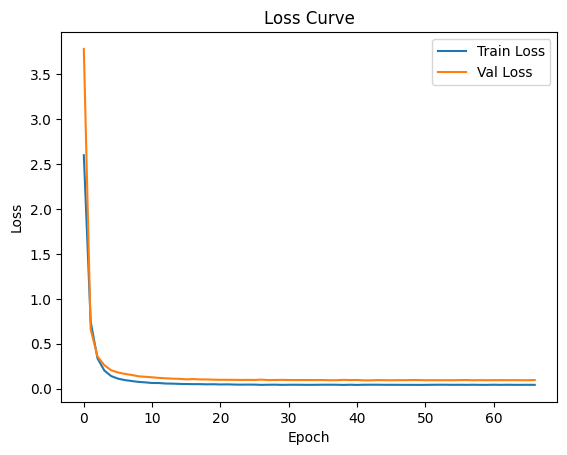

In [42]:
plt.figure()
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Loss Curve")
plt.show()

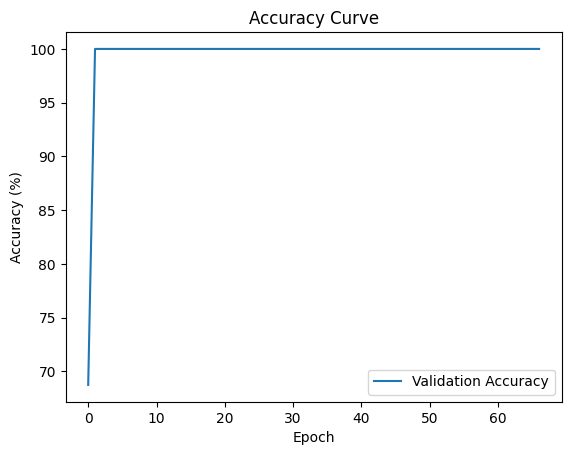

In [43]:
plt.figure()
plt.plot(val_accs, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.title("Accuracy Curve")
plt.show()

In [44]:
model.load_state_dict(
    torch.load("best_model.pth")
)

<All keys matched successfully>

In [45]:
@torch.no_grad()
def compute_identification_metrics(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    all_preds = []
    all_labels = []

    rank1 = 0
    rank5 = 0
    rank10 = 0
    total = 0

    for features, labels in loader:

        features = features.to(device)
        labels = labels.to(device)

        logits, _, _ = model(features)

        preds = logits.argmax(1)

        all_preds.extend(
            preds.cpu().numpy()
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

        top5 = logits.topk(
            k=min(5, logits.size(1)),
            dim=1
        ).indices

        top10 = logits.topk(
            k=min(10, logits.size(1)),
            dim=1
        ).indices

        rank1 += (preds == labels).sum().item()

        rank5 += (
            top5 == labels.unsqueeze(1)
        ).any(dim=1).sum().item()

        rank10 += (
            top10 == labels.unsqueeze(1)
        ).any(dim=1).sum().item()

        total += labels.size(0)

    return {
        "rank1": 100 * rank1 / total,
        "rank5": 100 * rank5 / total,
        "rank10": 100 * rank10 / total,
        "precision": precision_score(
            all_labels,
            all_preds,
            average="macro",
            zero_division=0
        ) * 100,
        "recall": recall_score(
            all_labels,
            all_preds,
            average="macro",
            zero_division=0
        ) * 100,
        "f1": f1_score(
            all_labels,
            all_preds,
            average="macro",
            zero_division=0
        ) * 100
    }

In [46]:
@torch.no_grad()
def compute_cmc(
    model,
    loader,
    device,
    max_rank=20
):

    model.eval()

    cmc = np.zeros(max_rank)
    total = 0

    for features, labels in loader:

        features = features.to(device)
        labels = labels.to(device)

        logits, _, _ = model(features)

        ranks = logits.argsort(
            dim=1,
            descending=True
        )

        for i in range(labels.size(0)):

            pos = (
                ranks[i] == labels[i]
            ).nonzero(
                as_tuple=True
            )[0].item()

            if pos < max_rank:
                cmc[pos:] += 1

        total += labels.size(0)

    return cmc / total

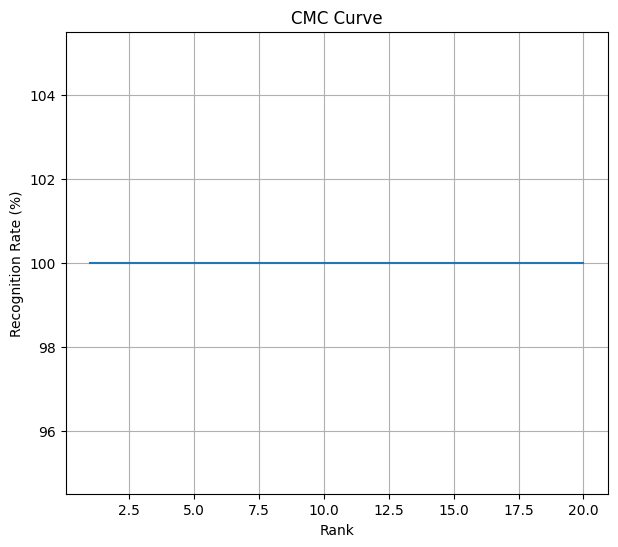

In [47]:
cmc = compute_cmc(
    model,
    test_loader,
    device
)

plt.figure(figsize=(7,6))

plt.plot(
    np.arange(1, len(cmc)+1),
    cmc * 100
)

plt.xlabel("Rank")
plt.ylabel("Recognition Rate (%)")
plt.title("CMC Curve")

plt.grid(True)
plt.show()

In [48]:
id_metrics = compute_identification_metrics(
    model,
    test_loader,
    criterion,
    device
)

print("\n===== Identification =====")
print(f"Rank-1 Accuracy : {id_metrics['rank1']:.2f}%")
print(f"Rank-5 Accuracy : {id_metrics['rank5']:.2f}%")
print(f"Rank-10 Accuracy: {id_metrics['rank10']:.2f}%")
print(f"Precision       : {id_metrics['precision']:.2f}%")
print(f"Recall          : {id_metrics['recall']:.2f}%")
print(f"F1 Score        : {id_metrics['f1']:.2f}%")


===== Identification =====
Rank-1 Accuracy : 100.00%
Rank-5 Accuracy : 100.00%
Rank-10 Accuracy: 100.00%
Precision       : 100.00%
Recall          : 100.00%
F1 Score        : 100.00%


In [49]:
@torch.no_grad()
def extract_fusion(loader, model, device):

    model.eval()

    fusion = []
    labels = []

    for features, target in loader:

        features = features.to(device)

        _, _, fused = model(features)

        fusion.append(fused.cpu())
        labels.append(target)

    fusion = torch.cat(fusion).numpy()
    labels = torch.cat(labels).numpy()

    return fusion, labels

In [50]:
warnings.filterwarnings("ignore")

X_train_fused, y_train = extract_fusion(
    train_loader,
    model,
    device
)

X_val_fused, y_val = extract_fusion(
    val_loader,
    model,
    device
)

X_test_fused, y_test = extract_fusion(
    test_loader,
    model,
    device
)

X_test_unknown_fused, y_test_unknown = extract_fusion(
   unknown_test_loader,
    model,
    device
)

print("Train:", X_train_fused.shape, y_train.shape)
print("Val  :", X_val_fused.shape, y_val.shape)
print("Test :", X_test_fused.shape, y_test.shape)
print("Test(unknown) :", X_test_unknown_fused.shape, y_test_unknown.shape)

Train: (1677, 1536) (1677,)
Val  : (560, 1536) (560,)
Test : (560, 1536) (560,)
Test(unknown) : (80, 1536) (80,)


In [51]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import normalize
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

X_train_ml = normalize(X_train_fused)
X_val_ml = normalize(X_val_fused)
X_test_ml = normalize(X_test_fused)

pipeline = make_pipeline(

    SelectKBest(
        score_func=mutual_info_classif,
        k=512
    ),

    StandardScaler(),

    SVC(
        kernel='rbf',
        probability=True
    )
)

pipeline.fit(X_train_ml, y_train)

val_pred = pipeline.predict(X_val_ml)

val_acc = accuracy_score(
    y_val,
    val_pred
)

print("Validation Accuracy:", val_acc)

y_pred = pipeline.predict(X_test_ml)

acc = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average='macro'
)

recall = recall_score(
    y_test,
    y_pred,
    average='macro'
)

f1 = f1_score(
    y_test,
    y_pred,
    average='macro'
)

print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

Validation Accuracy: 1.0
Accuracy  : 1.0000
Precision : 1.0000
Recall    : 1.0000
F1-Score  : 1.0000


In [52]:
from sklearn.svm import LinearSVC

svm = make_pipeline(
    SelectKBest(
        score_func=mutual_info_classif,
        k=512
    ),
    StandardScaler(),
    LinearSVC(
        C=1.0,
        class_weight='balanced',
        max_iter=10000
    )
)

svm.fit(X_train_ml, y_train)

val_pred = svm.predict(X_val_ml)
val_acc = accuracy_score(y_val, val_pred)

print("Validation Accuracy:", val_acc)

y_pred = svm.predict(X_test_ml)

acc = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average='macro'
)

recall = recall_score(
    y_test,
    y_pred,
    average='macro'
)

f1 = f1_score(
    y_test,
    y_pred,
    average='macro'
)

print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

Validation Accuracy: 1.0
Accuracy  : 1.0000
Precision : 1.0000
Recall    : 1.0000
F1-Score  : 1.0000


In [53]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(
    n_neighbors=5,
    metric='cosine'
)

knn.fit(X_train_ml, y_train)

y_pred = knn.predict(X_test_ml)

acc = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average='macro'
)

recall = recall_score(
    y_test,
    y_pred,
    average='macro'
)

f1 = f1_score(
    y_test,
    y_pred,
    average='macro'
)

print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

Accuracy  : 1.0000
Precision : 1.0000
Recall    : 1.0000
F1-Score  : 1.0000


In [54]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(
    max_iter=5000,
    class_weight='balanced'
)

lr.fit(X_train_ml, y_train)

y_pred = lr.predict(X_test_ml)

acc = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average='macro'
)

recall = recall_score(
    y_test,
    y_pred,
    average='macro'
)

f1 = f1_score(
    y_test,
    y_pred,
    average='macro'
)

print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

Accuracy  : 1.0000
Precision : 1.0000
Recall    : 1.0000
F1-Score  : 1.0000


In [55]:
@torch.no_grad()
def extract_embeddings(loader, model, device):

    model.eval()

    embeddings = []
    labels = []

    for features, target in loader:

        features = features.to(device)

        _, feat, _ = model(features)

        embeddings.append(feat.cpu())
        labels.append(target)

    embeddings = torch.cat(embeddings).numpy()
    labels = torch.cat(labels).numpy()

    return embeddings, labels

In [56]:
X_gallery, y_gallery = extract_embeddings(
    gallery_loader,
    model,
    device
)

X_gallery = normalize(X_gallery)

In [57]:
X_known, y_known = extract_embeddings(
    probe_loader,
    model,
    device
)

X_known = normalize(X_known)

In [58]:
X_unknown, y_unknown = extract_embeddings(
    unknown_test_loader,
    model,
    device
)

X_unknown = normalize(X_unknown)

In [59]:
svm = make_pipeline(

    SelectKBest(
        score_func=mutual_info_classif,
        k=256
    ),

    StandardScaler(),
     LinearSVC(
        C=1.0,
        class_weight='balanced',
        max_iter=10000
    )
)

svm.fit(X_gallery, y_gallery)

y_pred = svm.predict(X_known)

acc = accuracy_score(y_known, y_pred)

precision = precision_score(
    y_known,
    y_pred,
    average='macro'
)

recall = recall_score(
    y_known,
    y_pred,
    average='macro'
)

f1 = f1_score(
    y_known,
    y_pred,
    average='macro'
)
print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

Accuracy  : 1.0000
Precision : 1.0000
Recall    : 1.0000
F1-Score  : 1.0000


In [60]:
svc = make_pipeline(
    SelectKBest(
        score_func=mutual_info_classif,
        k=256
    ),
    StandardScaler(),
    SVC(
        kernel='rbf',
        probability=True
    )
)

svc.fit(X_gallery, y_gallery)

y_pred = svc.predict(X_known)

acc = accuracy_score(y_known, y_pred)

precision = precision_score(
    y_known,
    y_pred,
    average='macro'
)

recall = recall_score(
    y_known,
    y_pred,
    average='macro'
)

f1 = f1_score(
    y_known,
    y_pred,
    average='macro'
)

print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

Accuracy  : 0.9896
Precision : 0.9907
Recall    : 0.9896
F1-Score  : 0.9895


In [61]:
gallery_embeddings = X_gallery
gallery_labels = y_gallery

In [63]:
from sklearn.metrics.pairwise import cosine_similarity

def identify_probe(
    probe_embedding,
    gallery_embeddings,
    gallery_labels,
    threshold
):

    sims = cosine_similarity(
        probe_embedding.reshape(1,-1),
        gallery_embeddings
    )[0]

    best_idx = np.argmax(sims)

    best_sim = sims[best_idx]

    if best_sim < threshold:

        return -1, best_sim

    pred_label = gallery_labels[best_idx]

    return pred_label, best_sim

In [64]:
genuine_scores = []
impostor_scores = []

for emb, label in zip(X_known, y_known):

    sims = cosine_similarity(
        emb.reshape(1,-1),
        gallery_embeddings
    )[0]

    same_scores = sims[gallery_labels == label]
    diff_scores = sims[gallery_labels != label]

    genuine_scores.append(np.max(same_scores))
    impostor_scores.append(np.max(diff_scores))

print("Genuine scores :", len(genuine_scores))
print("Impostor scores:", len(impostor_scores))

Genuine scores : 96
Impostor scores: 96


In [75]:
threshold = 0.52
print("Threshold : ",threshold)

known_correct = 0
known_total = len(y_known)

for emb, label in zip(X_known, y_known):

    pred, sim = identify_probe(
    emb,
    gallery_embeddings,
    gallery_labels,
    threshold
)

    if pred == label:
        known_correct += 1

known_acc = 100 * known_correct / known_total

print("Known Identification =", known_acc)

correct_rejections = 0

for emb in X_unknown:

    pred, sim = identify_probe(
    emb,
    gallery_embeddings,
    gallery_labels,
    threshold
)

    if pred == -1:
        correct_rejections += 1

unknown_rejection_rate = (
    100 * correct_rejections /
    len(X_unknown)
)

print(
    "Unknown Rejection Rate:",
    unknown_rejection_rate
)

Threshold :  0.52
Known Identification = 97.91666666666667
Unknown Rejection Rate: 97.5


In [66]:
unknown_scores = []

for emb in X_unknown:

    emb = emb / np.linalg.norm(emb)

    sims = gallery_embeddings @ emb

    unknown_scores.append(np.max(sims))

In [67]:
print("Worst genuine :", np.min(genuine_scores))
print("Best impostor :", np.max(unknown_scores))

Worst genuine : 0.515136
Best impostor : 0.55194753


In [76]:
print("Threshold : ",threshold)
print(f"DIR : {known_acc:.2f}%")
print(f"URR : {unknown_rejection_rate:.2f}%")

Threshold :  0.52
DIR : 97.92%
URR : 97.50%


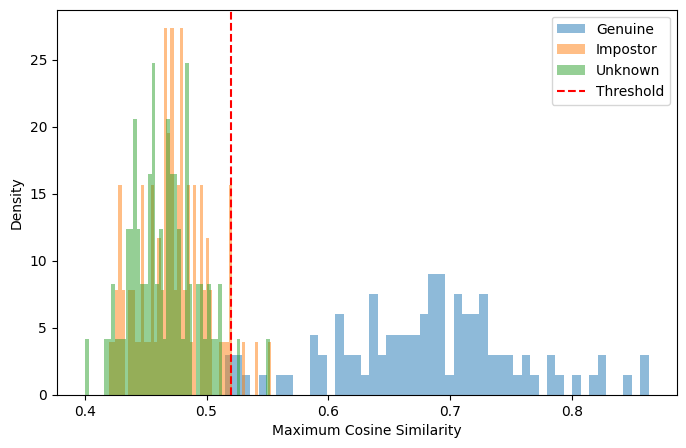

In [77]:
plt.figure(figsize=(8,5))

plt.hist(genuine_scores,bins=50,alpha=0.5,density=True,label="Genuine")
plt.hist(impostor_scores,bins=50,alpha=0.5,density=True,label="Impostor")
plt.hist(unknown_scores,bins=50,alpha=0.5,density=True,label="Unknown")

plt.axvline(threshold,color="red",linestyle="--",label="Threshold")

plt.xlabel("Maximum Cosine Similarity")
plt.ylabel("Density")
plt.legend()
plt.show()


In [70]:
import numpy as np
from scipy.stats import wasserstein_distance

def biometric_statistics(genuine, impostor, unknown=None):

    genuine = np.asarray(genuine)
    impostor = np.asarray(impostor)

    mu_g = np.mean(genuine)
    mu_i = np.mean(impostor)

    std_g = np.std(genuine)
    std_i = np.std(impostor)
    
    d_prime = (mu_g - mu_i) / np.sqrt((std_g**2 + std_i**2) / 2)
    
    fdr = ((mu_g - mu_i)**2) / (std_g**2 + std_i**2)
    
    margin = mu_g - mu_i
    
    overlap = (std_g + std_i) / abs(mu_g - mu_i)

    wd = wasserstein_distance(genuine, impostor)

    print("="*60)
    print(f"Genuine Mean          : {mu_g:.4f}")
    print(f"Impostor Mean         : {mu_i:.4f}")
    print(f"Genuine Std           : {std_g:.4f}")
    print(f"Impostor Std          : {std_i:.4f}")
    print("-"*60)
    print(f"d-prime               : {d_prime:.4f}")
    print(f"Fisher Ratio (FDR)    : {fdr:.4f}")
    print(f"Margin                : {margin:.4f}")
    print(f"Overlap Index         : {overlap:.4f}")
    print(f"Wasserstein Distance  : {wd:.4f}")

    if unknown is not None:
        unknown = np.asarray(unknown)

        mu_u = np.mean(unknown)
        std_u = np.std(unknown)

        d_prime_unknown = (mu_g - mu_u) / np.sqrt((std_g**2 + std_u**2)/2)

        fdr_unknown = ((mu_g-mu_u)**2)/(std_g**2+std_u**2)

        wd_unknown = wasserstein_distance(genuine, unknown)

        print("-"*60)
        print(f"Unknown Mean          : {mu_u:.4f}")
        print(f"Unknown Std           : {std_u:.4f}")
        print(f"Genuine-Unknown d'    : {d_prime_unknown:.4f}")
        print(f"Genuine-Unknown FDR   : {fdr_unknown:.4f}")
        print(f"Genuine-Unknown WD    : {wd_unknown:.4f}")

    print("="*60)

    return {
        "d_prime": d_prime,
        "FDR": fdr,
        "Margin": margin,
        "Overlap": overlap,
        "Wasserstein": wd
    }

In [71]:
print("combined Arcitecture with multilevel nn")

cnn_stats = biometric_statistics(
    genuine_scores,
    impostor_scores,
    unknown_scores
)

combined Arcitecture with multilevel nn
Genuine Mean          : 0.6818
Impostor Mean         : 0.4729
Genuine Std           : 0.0749
Impostor Std          : 0.0273
------------------------------------------------------------
d-prime               : 3.7044
Fisher Ratio (FDR)    : 6.8613
Margin                : 0.2089
Overlap Index         : 0.4895
Wasserstein Distance  : 0.2089
------------------------------------------------------------
Unknown Mean          : 0.4644
Unknown Std           : 0.0269
Genuine-Unknown d'    : 3.8620
Genuine-Unknown FDR   : 7.4573
Genuine-Unknown WD    : 0.2174


In [72]:
from sklearn.neighbors import NearestCentroid

clf = NearestCentroid()
clf.fit(gallery_embeddings, gallery_labels)
pred = clf.predict(X_known)

print("Nearest Centroid Accuracy:",accuracy_score(y_known, pred))

Nearest Centroid Accuracy: 1.0


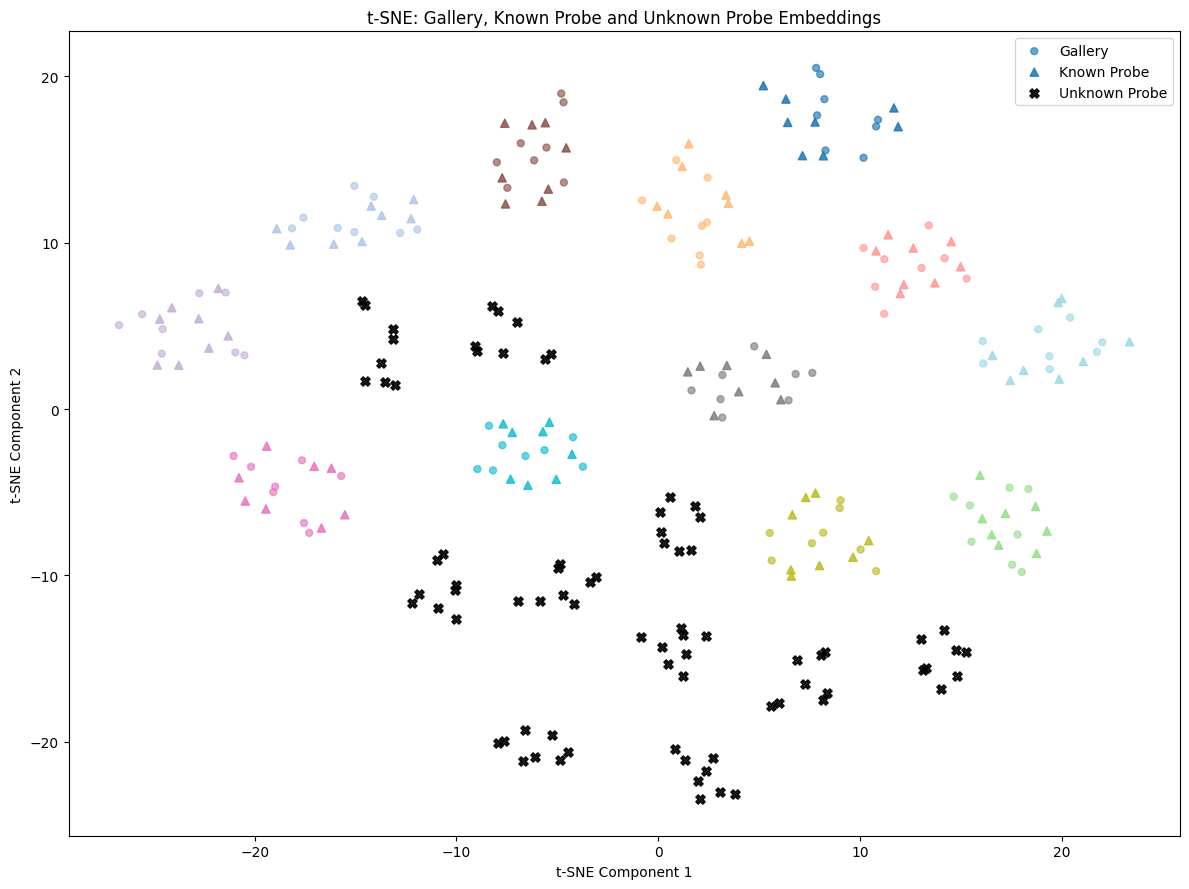

In [73]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import numpy as np

# Combine embeddings
X_combined = np.concatenate(
    [X_gallery, X_known, X_unknown], axis=0
)

# Joint t-SNE
tsne = TSNE(
    n_components=2,
    perplexity=30,
    random_state=42,
    init="pca",
    learning_rate="auto"
)

X_tsne = tsne.fit_transform(X_combined)

# Separate coordinates
n_gallery = len(X_gallery)
n_probe = len(X_known)

gallery_tsne = X_tsne[:n_gallery]
probe_tsne = X_tsne[n_gallery:n_gallery+n_probe]
unknown_tsne = X_tsne[n_gallery+n_probe:]

# Plot
plt.figure(figsize=(12, 9))

plt.scatter(
    gallery_tsne[:, 0], gallery_tsne[:, 1],
    c=y_gallery, cmap="tab20",
    marker="o", s=25, alpha=0.65,
    label="Gallery"
)

plt.scatter(
    probe_tsne[:, 0], probe_tsne[:, 1],
    c=y_known, cmap="tab20",
    marker="^", s=35, alpha=0.85,
    label="Known Probe"
)

plt.scatter(
    unknown_tsne[:, 0], unknown_tsne[:, 1],
    color="black",
    marker="X", s=45, alpha=0.9,
    label="Unknown Probe"
)

plt.title("t-SNE: Gallery, Known Probe and Unknown Probe Embeddings")
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.legend()
plt.tight_layout()
plt.show()

In [74]:
np.save('/kaggle/working/X_gallery_0.npy', X_gallery)
np.save('/kaggle/working/y_gallery_0.npy', y_gallery)
np.save('/kaggle/working/X_known_0.npy', X_known)
np.save('/kaggle/working/y_known_0.npy', y_known)
np.save('/kaggle/working/X_unknown_0.npy', X_unknown)
np.save('/kaggle/working/y_unknown_0.npy', y_unknown)

torch.save(
    model.state_dict(),
    '/kaggle/working/model_weights_0.pth'
)

print("Embeddings and labels and model are saved successfully!")

Embeddings and labels and model are saved successfully!
